In [ ]:
import os
import kagglehub

# Download WESAD (Empatica E4 + Chest Wearable Dataset) from Kaggle
dataset_path = kagglehub.dataset_download("orvile/wesad-wearable-stress-affect-detection-dataset")

print("Downloaded to:", dataset_path)
for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    if level <= 2:
        indent = "  " * level
        print(f"{indent}{os.path.basename(root)}/ (dirs: {len(dirs)}, files: {len(files)})")
        if files:
            print(f"{indent}  sample files: {sorted(files)[:6]}")

Using Colab cache for faster access to the 'wesad-wearable-stress-affect-detection-dataset' dataset.
Downloaded to: /kaggle/input/wesad-wearable-stress-affect-detection-dataset
wesad-wearable-stress-affect-detection-dataset/ (dirs: 1, files: 0)
  WESAD/ (dirs: 15, files: 1)
    sample files: ['wesad_readme.pdf']
    S14/ (dirs: 1, files: 4)
      sample files: ['S14.pkl', 'S14_quest.csv', 'S14_readme.txt', 'S14_respiban.txt']
    S11/ (dirs: 1, files: 4)
      sample files: ['S11.pkl', 'S11_quest.csv', 'S11_readme.txt', 'S11_respiban.txt']
    S13/ (dirs: 1, files: 4)
      sample files: ['S13.pkl', 'S13_quest.csv', 'S13_readme.txt', 'S13_respiban.txt']
    S10/ (dirs: 1, files: 4)
      sample files: ['S10.pkl', 'S10_quest.csv', 'S10_readme.txt', 'S10_respiban.txt']
    S8/ (dirs: 1, files: 4)
      sample files: ['S8.pkl', 'S8_quest.csv', 'S8_readme.txt', 'S8_respiban.txt']
    S5/ (dirs: 1, files: 4)
      sample files: ['S5.pkl', 'S5_quest.csv', 'S5_readme.txt', 'S5_respiban.txt']


Top-level keys: ['signal', 'label', 'subject']
Wrist (Empatica E4) sensors: ['ACC', 'BVP', 'EDA', 'TEMP']

Total session duration: 101.3 minutes
BVP shape (64 Hz):  (389056, 1)
ACC shape (32 Hz):  (194528, 3)
EDA shape (4 Hz):   (24316, 1)
TEMP shape (4 Hz):  (24316, 1)

Time spent in each state (minutes):
  Label 0 (Transient): 51.02 min
  Label 1 (Baseline): 19.07 min
  Label 2 (Stress): 10.25 min
  Label 3 (Amusement): 6.03 min
  Label 4 (Meditation): 12.80 min
  Label 6 (Other): 1.08 min
  Label 7 (Other): 1.07 min


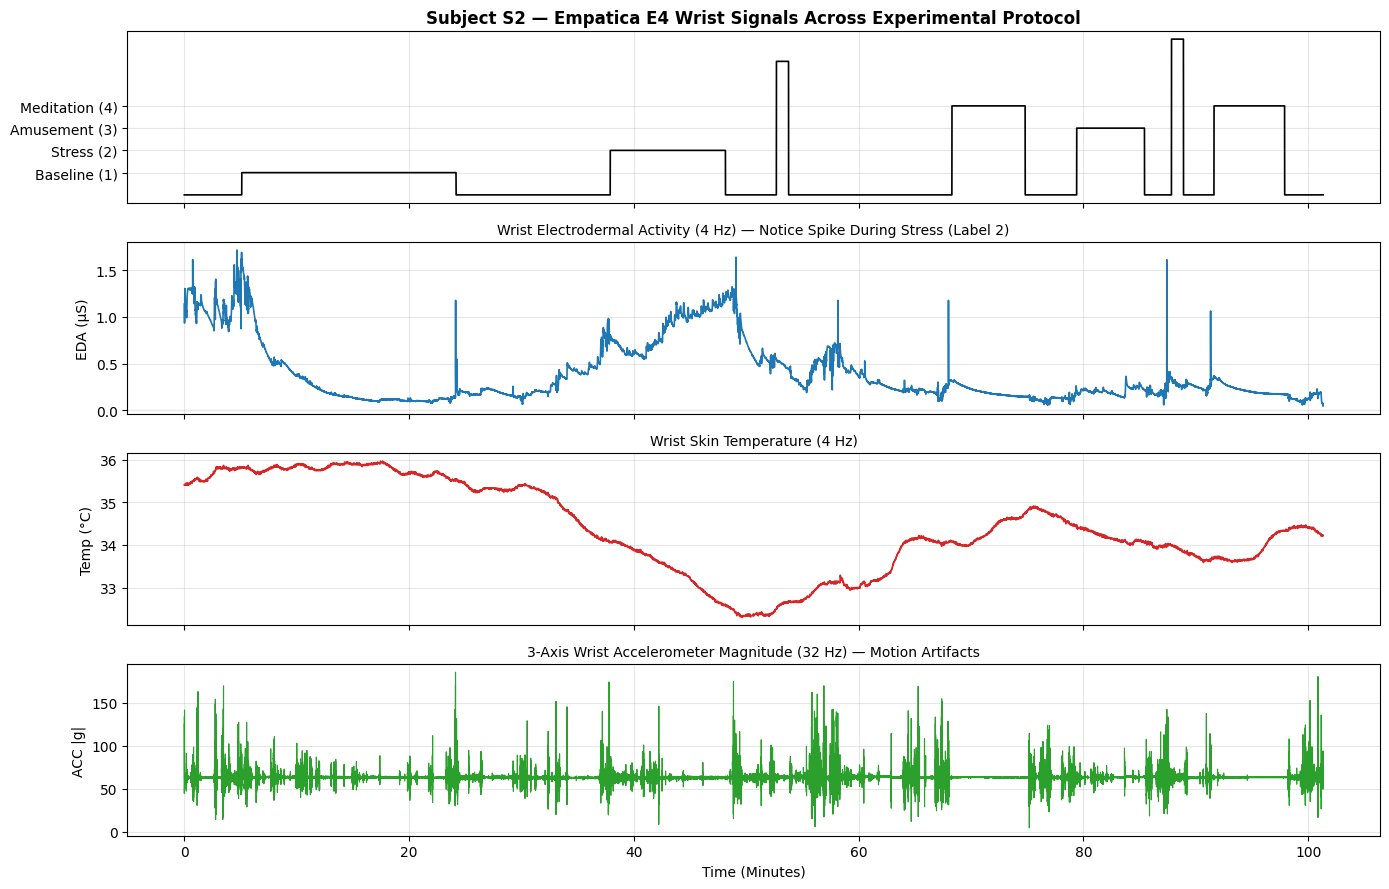

In [ ]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = "/kaggle/input/wesad-wearable-stress-affect-detection-dataset/WESAD"

# Load Subject S2 (must use encoding='latin1' because WESAD was saved in Python 2/3 pickle format)
with open(f"{DATA_DIR}/S2/S2.pkl", "rb") as f:
    s2 = pickle.load(f, encoding="latin1")

print("Top-level keys:", list(s2.keys()))
print("Wrist (Empatica E4) sensors:", list(s2["signal"]["wrist"].keys()))

# Check exact array shapes and duration in minutes
wrist = s2["signal"]["wrist"]
labels_700hz = s2["label"]

print(f"\nTotal session duration: {len(labels_700hz) / 700 / 60:.1f} minutes")
print(f"BVP shape (64 Hz):  {wrist['BVP'].shape}")
print(f"ACC shape (32 Hz):  {wrist['ACC'].shape}")
print(f"EDA shape (4 Hz):   {wrist['EDA'].shape}")
print(f"TEMP shape (4 Hz):  {wrist['TEMP'].shape}")

# Check label distribution (1=Baseline, 2=Stress, 3=Amusement, 4=Meditation)
unique_lbls, counts = np.unique(labels_700hz, return_counts=True)
lbl_names = {0: "Transient", 1: "Baseline", 2: "Stress", 3: "Amusement", 4: "Meditation", 5: "Other", 6: "Other", 7: "Other"}
print("\nTime spent in each state (minutes):")
for l, c in zip(unique_lbls, counts):
    print(f"  Label {l} ({lbl_names.get(l, 'Other')}): {c / 700 / 60:.2f} min")

# Plot the entire ~100-minute Empatica E4 session for Subject S2
fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)

t_4hz = np.arange(len(wrist["EDA"])) / 4.0 / 60.0       # time in minutes
t_32hz = np.arange(len(wrist["ACC"])) / 32.0 / 60.0
t_700hz = np.arange(len(labels_700hz)) / 700.0 / 60.0

# 1. Ground truth protocol timeline
axes[0].plot(t_700hz, labels_700hz, color="black", linewidth=1.2)
axes[0].set_yticks([1, 2, 3, 4])
axes[0].set_yticklabels(["Baseline (1)", "Stress (2)", "Amusement (3)", "Meditation (4)"])
axes[0].set_title("Subject S2 — Empatica E4 Wrist Signals Across Experimental Protocol", fontsize=12, fontweight="bold")
axes[0].grid(alpha=0.3)

# 2. Electrodermal Activity (Sweat / Sympathetic Arousal)
axes[1].plot(t_4hz, wrist["EDA"], color="#1f77b4", linewidth=1.2)
axes[1].set_ylabel("EDA (µS)")
axes[1].set_title("Wrist Electrodermal Activity (4 Hz) — Notice Spike During Stress (Label 2)", fontsize=10)
axes[1].grid(alpha=0.3)

# 3. Skin Temperature
axes[2].plot(t_4hz, wrist["TEMP"], color="#d62728", linewidth=1.2)
axes[2].set_ylabel("Temp (°C)")
axes[2].set_title("Wrist Skin Temperature (4 Hz)", fontsize=10)
axes[2].grid(alpha=0.3)

# 4. Accelerometer Magnitude (Wrist Movement)
acc_mag = np.linalg.norm(wrist["ACC"], axis=1)
axes[3].plot(t_32hz, acc_mag, color="#2ca02c", linewidth=0.8)
axes[3].set_ylabel("ACC |g|")
axes[3].set_xlabel("Time (Minutes)")
axes[3].set_title("3-Axis Wrist Accelerometer Magnitude (32 Hz) — Motion Artifacts", fontsize=10)
axes[3].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import os, glob, pickle
import numpy as np
import pandas as pd
from scipy.signal import butter, filtfilt, find_peaks

DATA_DIR = "/kaggle/input/wesad-wearable-stress-affect-detection-dataset/WESAD"
SUBJECTS = sorted([os.path.basename(p) for p in glob.glob(f"{DATA_DIR}/S*")])
print("Found subjects:", SUBJECTS)

def bandpass_bvp(sig, fs=64.0):
    b, a = butter(3, [0.7 / (0.5 * fs), 3.5 / (0.5 * fs)], btype="band")
    return filtfilt(b, a, sig)

def lowpass_eda(sig, fs=4.0):
    b, a = butter(2, 0.5 / (0.5 * fs), btype="low")
    return filtfilt(b, a, sig)

LABEL_MAP = {1: 0, 2: 1, 3: 2}  # 0=Baseline, 1=Stress, 2=Amusement
WIN_SEC = 30
STEP_SEC = 15

all_sequences = []   # Shape: [N, 6, 120] -> 6 channels at 4 Hz for 30s
all_features = []    # Shape: [N, 18] domain physiological + SQI features
meta_rows = []

for subj in SUBJECTS:
    pkl_path = f"{DATA_DIR}/{subj}/{subj}.pkl"
    with open(pkl_path, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    wrist = data["signal"]["wrist"]
    bvp = wrist["BVP"].squeeze()          # 64 Hz
    acc = wrist["ACC"]                    # 32 Hz (N, 3)
    eda = wrist["EDA"].squeeze()          # 4 Hz
    temp = wrist["TEMP"].squeeze()        # 4 Hz
    labels = data["label"].squeeze()      # 700 Hz

    # Clean signals
    bvp_clean = bandpass_bvp(bvp, fs=64.0)
    eda_clean = lowpass_eda(eda, fs=4.0)
    acc_mag = np.linalg.norm(acc, axis=1)

    total_sec = int(min(len(eda) / 4, len(bvp) / 64, len(acc) / 32, len(labels) / 700))

    for start_s in range(0, total_sec - WIN_SEC + 1, STEP_SEC):
        end_s = start_s + WIN_SEC

        # Check label homogeneity in 700 Hz label array
        lbl_seg = labels[start_s * 700 : end_s * 700]
        vals, cnts = np.unique(lbl_seg, return_counts=True)
        dom_lbl = int(vals[np.argmax(cnts)])
        purity = cnts.max() / len(lbl_seg)

        if dom_lbl not in LABEL_MAP or purity < 0.90:
            continue

        # Slice each sensor at its native rate
        bvp_w = bvp_clean[start_s * 64 : end_s * 64]       # 1920 samples
        acc_w = acc[start_s * 32 : end_s * 32]             # 960 x 3 samples
        acc_mag_w = acc_mag[start_s * 32 : end_s * 32]     # 960 samples
        eda_w = eda_clean[start_s * 4 : end_s * 4]         # 120 samples
        temp_w = temp[start_s * 4 : end_s * 4]             # 120 samples

        # 1. Resample all channels to 4 Hz (120 steps) for 1D-CNN sequence input
        bvp_4hz = bvp_w.reshape(120, 16).mean(axis=1)
        acc_x_4hz = acc_w[:, 0].reshape(120, 8).mean(axis=1)
        acc_y_4hz = acc_w[:, 1].reshape(120, 8).mean(axis=1)
        acc_z_4hz = acc_w[:, 2].reshape(120, 8).mean(axis=1)
        seq_tensor = np.stack([bvp_4hz, eda_w, temp_w, acc_x_4hz, acc_y_4hz, acc_z_4hz], axis=0)

        # 2. Accelerometer Motion-Artifact Signal Quality Index (SQI in [0, 1])
        acc_std = float(np.std(acc_mag_w))
        sqi = float(np.exp(-0.08 * acc_std))

        # 3. Extract physiological HRV, EDA, Temperature & Motion features
        peaks, _ = find_peaks(bvp_w, distance=int(0.4 * 64), prominence=np.std(bvp_w) * 0.4)
        if len(peaks) >= 4:
            rr_ms = np.diff(peaks) / 64.0 * 1000.0
            bpm = float(60000.0 / np.mean(rr_ms))
            sdnn = float(np.std(rr_ms))
            rmssd = float(np.sqrt(np.mean(np.diff(rr_ms) ** 2)))
        else:
            bpm, sdnn, rmssd = 75.0, 40.0, 30.0

        eda_diff = np.diff(eda_w)
        scr_peaks = float(np.sum(eda_diff > 0.01))
        temp_slope = float((temp_w[-1] - temp_w[0]) / (WIN_SEC / 60.0))  # °C per minute

        feat_vec = np.array([
            bpm, sdnn, rmssd, float(np.std(bvp_w)),
            float(np.mean(eda_w)), float(np.std(eda_w)), float(eda_w[-1] - eda_w[0]), scr_peaks, float(np.max(eda_diff)),
            float(np.mean(temp_w)), float(np.std(temp_w)), temp_slope,
            float(np.mean(acc_mag_w)), acc_std, float(np.max(acc_mag_w) - np.min(acc_mag_w)),
            sqi, bpm * sqi, rmssd * sqi
        ], dtype=np.float32)

        all_sequences.append(seq_tensor.astype(np.float32))
        all_features.append(feat_vec)
        meta_rows.append({
            "subject": subj,
            "start_sec": start_s,
            "label": LABEL_MAP[dom_lbl],
            "state": {0: "Baseline", 1: "Stress", 2: "Amusement"}[LABEL_MAP[dom_lbl]],
            "sqi": sqi,
            "bpm": bpm,
            "eda_mean": float(np.mean(eda_w)),
            "temp_mean": float(np.mean(temp_w))
        })

X_seq = np.stack(all_sequences)
X_feat = np.stack(all_features)
meta_df = pd.DataFrame(meta_rows)

np.savez_compressed("/content/wesad_windows.npz", X_seq=X_seq, X_feat=X_feat)
meta_df.to_csv("/content/wesad_meta.csv", index=False)

print(f"\nExtracted {len(meta_df)} clean 30-second windows across {len(SUBJECTS)} subjects!")
print(f"Sequence tensor shape: {X_seq.shape} | Feature matrix shape: {X_feat.shape}")
print("\nClass distribution:")
print(meta_df["state"].value_counts())
print(f"\nAverage Motion Signal Quality Index (SQI) by state:")
print(meta_df.groupby("state")["sqi"].mean().round(3))

Found subjects: ['S10', 'S11', 'S13', 'S14', 'S15', 'S16', 'S17', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9']

Extracted 2140 clean 30-second windows across 15 subjects!
Sequence tensor shape: (2140, 6, 120) | Feature matrix shape: (2140, 18)

Class distribution:
state
Baseline     1149
Stress        642
Amusement     349
Name: count, dtype: int64

Average Motion Signal Quality Index (SQI) by state:
state
Amusement    0.932
Baseline     0.874
Stress       0.754
Name: sqi, dtype: float64


In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, balanced_accuracy_score, classification_report

# Load saved windows and metadata
data = np.load("/content/wesad_windows.npz")
X_feat = data["X_feat"]
meta_df = pd.read_csv("/content/wesad_meta.csv")
y = meta_df["label"].values
subjects = meta_df["subject"].values
unique_subjects = sorted(meta_df["subject"].unique())

# Build Zero-Shot Subject-Calibrated Features (normalized against each subject's initial 3 resting windows)
X_cal = np.zeros_like(X_feat)
for subj in unique_subjects:
    subj_mask = (subjects == subj)
    subj_X = X_feat[subj_mask]
    subj_y = y[subj_mask]

    # Use the first 3 Baseline (label == 0) windows as the user's resting calibration period
    rest_windows = subj_X[subj_y == 0][:3]
    rest_mean = rest_windows.mean(axis=0)
    rest_std = rest_windows.std(axis=0) + 1e-4

    # Keep SQI & raw motion features un-shifted (cols 12..17), normalize physiological channels (cols 0..11)
    cal_subj_X = subj_X.copy()
    cal_subj_X[:, :12] = (subj_X[:, :12] - rest_mean[:12]) / rest_std[:12]
    X_cal[subj_mask] = cal_subj_X

def run_loso_benchmark(X_matrix, name):
    oof_preds = np.zeros_like(y)
    subj_f1s = []

    for test_subj in unique_subjects:
        test_mask = (subjects == test_subj)
        train_mask = ~test_mask

        clf = HistGradientBoostingClassifier(
            max_iter=150,
            learning_rate=0.05,
            max_depth=5,
            l2_regularization=1.0,
            class_weight="balanced",
            random_state=42
        )
        clf.fit(X_matrix[train_mask], y[train_mask])
        preds = clf.predict(X_matrix[test_mask])
        oof_preds[test_mask] = preds
        subj_f1s.append(f1_score(y[test_mask], preds, average="macro"))

    macro_f1 = f1_score(y, oof_preds, average="macro")
    bal_acc = balanced_accuracy_score(y, oof_preds)
    print(f"--- {name} ---")
    print(f"Overall 15-Subject LOSO Macro-F1:          {macro_f1:.4f}")
    print(f"Overall 15-Subject LOSO Balanced Accuracy: {bal_acc:.4f}")
    print(f"Mean Per-Subject Macro-F1:                 {np.mean(subj_f1s):.4f} ± {np.std(subj_f1s):.4f}\n")
    return oof_preds, subj_f1s

preds_raw, f1s_raw = run_loso_benchmark(X_feat, "1. Uncalibrated Wearable Features (Standard Baseline)")
preds_cal, f1s_cal = run_loso_benchmark(X_cal,  "2. + Zero-Shot Subject Baseline Calibration")

print("Detailed Classification Report (Zero-Shot Calibrated LOSO):")
print(classification_report(y, preds_cal, target_names=["Baseline", "Stress", "Amusement"], digits=4))

--- 1. Uncalibrated Wearable Features (Standard Baseline) ---
Overall 15-Subject LOSO Macro-F1:          0.6225
Overall 15-Subject LOSO Balanced Accuracy: 0.6261
Mean Per-Subject Macro-F1:                 0.5744 ± 0.0864

--- 2. + Zero-Shot Subject Baseline Calibration ---
Overall 15-Subject LOSO Macro-F1:          0.6652
Overall 15-Subject LOSO Balanced Accuracy: 0.6614
Mean Per-Subject Macro-F1:                 0.6236 ± 0.1303

Detailed Classification Report (Zero-Shot Calibrated LOSO):
              precision    recall  f1-score   support

    Baseline     0.8368    0.8790    0.8574      1149
      Stress     0.8023    0.7586    0.7798       642
   Amusement     0.3712    0.3467    0.3585       349

    accuracy                         0.7561      2140
   macro avg     0.6701    0.6614    0.6652      2140
weighted avg     0.7505    0.7561    0.7528      2140



In [ ]:
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score, balanced_accuracy_score, classification_report

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Load raw sequence tensors [2140, 6, 120] and calibrated features [2140, 18]
data = np.load("/content/wesad_windows.npz")
X_seq_raw = data["X_seq"]   # Channels: 0=BVP, 1=EDA, 2=TEMP, 3=ACC_x, 4=ACC_y, 5=ACC_z
X_feat = data["X_feat"]
meta_df = pd.read_csv("/content/wesad_meta.csv")
y = meta_df["label"].values
subjects = meta_df["subject"].values
unique_subjects = sorted(meta_df["subject"].unique())

# Zero-Shot Baseline Calibration for BOTH sequence channels (BVP, EDA, TEMP) and tabular features
X_seq_cal = np.zeros_like(X_seq_raw)
X_feat_cal = np.zeros_like(X_feat)

for subj in unique_subjects:
    m = (subjects == subj)
    s_seq = X_seq_raw[m].copy()
    s_feat = X_feat[m].copy()
    s_y = y[m]

    # Calibrate physiological channels (0: BVP, 1: EDA, 2: TEMP) using first 3 resting Baseline windows
    rest_seq = s_seq[s_y == 0][:3]
    seq_mean = rest_seq[:, :3, :].mean(axis=(0, 2), keepdims=True)
    seq_std = rest_seq[:, :3, :].std(axis=(0, 2), keepdims=True) + 1e-4
    s_seq[:, :3, :] = (s_seq[:, :3, :] - seq_mean) / seq_std

    # Standardize 3-axis ACC per window (captures dynamic wrist jitter)
    acc_mean = s_seq[:, 3:, :].mean(axis=2, keepdims=True)
    acc_std = s_seq[:, 3:, :].std(axis=2, keepdims=True) + 1e-4
    s_seq[:, 3:, :] = (s_seq[:, 3:, :] - acc_mean) / acc_std
    X_seq_cal[m] = np.clip(s_seq, -10.0, 10.0)

    # Calibrate physiological summary features (cols 0..11)
    rest_feat = s_feat[s_y == 0][:3]
    f_mean = rest_feat[:, :12].mean(axis=0)
    f_std = rest_feat[:, :12].std(axis=0) + 1e-4
    s_feat[:, :12] = (s_feat[:, :12] - f_mean) / f_std
    X_feat_cal[m] = np.clip(s_feat, -10.0, 10.0)

# 2. Define the SQI-Gated Multi-Scale 1D-CNN + Physiological Fusion Architecture
class SQIGatedMultimodalNet(nn.Module):
    def __init__(self, seq_channels=6, feat_dim=18, num_classes=3):
        super().__init__()
        # Multi-scale temporal feature extractors (fast spikes k=3 vs slow trends k=11)
        self.branch_fast = nn.Sequential(
            nn.Conv1d(seq_channels, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm1d(32),
            nn.GELU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm1d(64),
            nn.GELU(),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten()
        )
        self.branch_slow = nn.Sequential(
            nn.Conv1d(seq_channels, 32, kernel_size=11, padding=5, bias=False),
            nn.BatchNorm1d(32),
            nn.GELU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=7, padding=3, bias=False),
            nn.BatchNorm1d(64),
            nn.GELU(),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten()
        )

        # Accelerometer SQI Reliability Gate: modulates temporal features based on motion artifact level
        self.sqi_gate = nn.Sequential(
            nn.Linear(4, 32),  # Takes [acc_mean, acc_std, acc_range, sqi]
            nn.GELU(),
            nn.Linear(32, 128),
            nn.Sigmoid()
        )

        # Calibrated domain feature branch
        self.feat_net = nn.Sequential(
            nn.Linear(feat_dim, 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Dropout(0.25)
        )

        # Final classifier
        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(128 + 64, 64),
            nn.GELU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, seq_x, feat_x):
        temp_emb = torch.cat([self.branch_fast(seq_x), self.branch_slow(seq_x)], dim=1)  # [B, 128]
        motion_ctx = feat_x[:, 12:16]  # [acc_mean, acc_std, acc_range, sqi]
        gate = self.sqi_gate(motion_ctx)
        gated_temp = temp_emb * gate

        dom_emb = self.feat_net(feat_x)  # [B, 64]
        return self.classifier(torch.cat([gated_temp, dom_emb], dim=1))

# 3. Run full 15-Fold Leave-One-Subject-Out (LOSO) training & evaluation
torch.manual_seed(42)
np.random.seed(42)

oof_probs = np.zeros((len(y), 3), dtype=np.float32)
subj_f1s = []
t_start = time.time()

print(f"Training SQI-Gated Multimodal 1D-CNN across 15 LOSO subjects on {device}...\n")

for fold_idx, test_subj in enumerate(unique_subjects, 1):
    test_mask = (subjects == test_subj)
    train_mask = ~test_mask

    # Standardize tabular features strictly inside each training fold (zero leakage!)
    f_mu = X_feat_cal[train_mask].mean(axis=0, keepdims=True)
    f_sd = X_feat_cal[train_mask].std(axis=0, keepdims=True) + 1e-5
    X_tr_f = (X_feat_cal[train_mask] - f_mu) / f_sd
    X_te_f = (X_feat_cal[test_mask] - f_mu) / f_sd

    tr_ds = TensorDataset(
        torch.tensor(X_seq_cal[train_mask], dtype=torch.float32),
        torch.tensor(X_tr_f, dtype=torch.float32),
        torch.tensor(y[train_mask], dtype=torch.long)
    )
    te_ds = TensorDataset(
        torch.tensor(X_seq_cal[test_mask], dtype=torch.float32),
        torch.tensor(X_te_f, dtype=torch.float32)
    )

    tr_loader = DataLoader(tr_ds, batch_size=64, shuffle=True)
    te_loader = DataLoader(te_ds, batch_size=128, shuffle=False)

    # Inverse-frequency class weights to boost minority Amusement & Stress recall
    cls_counts = np.bincount(y[train_mask])
    cls_weights = torch.tensor(len(y[train_mask]) / (3.0 * cls_counts), dtype=torch.float32, device=device)

    model = SQIGatedMultimodalNet().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1.5e-3, weight_decay=1e-3)
    criterion = nn.CrossEntropyLoss(weight=cls_weights, label_smoothing=0.05)

    model.train()
    for epoch in range(25):
        for bx_seq, bx_feat, by in tr_loader:
            bx_seq, bx_feat, by = bx_seq.to(device), bx_feat.to(device), by.to(device)
            optimizer.zero_grad()
            loss = criterion(model(bx_seq, bx_feat), by)
            loss.backward()
            optimizer.step()

    model.eval()
    fold_probs = []
    with torch.no_grad():
        for bx_seq, bx_feat in te_loader:
            logits = model(bx_seq.to(device), bx_feat.to(device))
            fold_probs.append(torch.softmax(logits, dim=1).cpu().numpy())

    fold_probs = np.vstack(fold_probs)
    oof_probs[test_mask] = fold_probs
    f1_s = f1_score(y[test_mask], fold_probs.argmax(axis=1), average="macro")
    subj_f1s.append(f1_s)
    print(f"Fold {fold_idx:02d}/15 | Unseen Test Subject: {test_subj:3s} | Macro-F1: {f1_s:.4f}")

oof_preds = oof_probs.argmax(axis=1)
np.savez("/content/wesad_loso_results.npz", oof_probs=oof_probs, oof_preds=oof_preds, y_true=y, subjects=subjects)

print(f"\n================ 15-SUBJECT LOSO DEEP MULTIMODAL REPORT ({time.time()-t_start:.1f}s) ================")
print(f"Overall 15-Subject LOSO Macro-F1:          {f1_score(y, oof_preds, average='macro'):.4f}")
print(f"Overall 15-Subject LOSO Balanced Accuracy: {balanced_accuracy_score(y, oof_preds):.4f}")
print(f"Mean Per-Subject Macro-F1:                 {np.mean(subj_f1s):.4f} ± {np.std(subj_f1s):.4f}")
print("=========================================================================================\n")
print(classification_report(y, oof_preds, target_names=["Baseline", "Stress", "Amusement"], digits=4))

Training SQI-Gated Multimodal 1D-CNN across 15 LOSO subjects on cpu...

Fold 01/15 | Unseen Test Subject: S10 | Macro-F1: 0.7352
Fold 02/15 | Unseen Test Subject: S11 | Macro-F1: 0.8619
Fold 03/15 | Unseen Test Subject: S13 | Macro-F1: 0.6157
Fold 04/15 | Unseen Test Subject: S14 | Macro-F1: 0.4221
Fold 05/15 | Unseen Test Subject: S15 | Macro-F1: 0.7653
Fold 06/15 | Unseen Test Subject: S16 | Macro-F1: 0.6422
Fold 07/15 | Unseen Test Subject: S17 | Macro-F1: 0.4985
Fold 08/15 | Unseen Test Subject: S2  | Macro-F1: 0.5144
Fold 09/15 | Unseen Test Subject: S3  | Macro-F1: 0.7499
Fold 10/15 | Unseen Test Subject: S4  | Macro-F1: 0.6032
Fold 11/15 | Unseen Test Subject: S5  | Macro-F1: 0.6285
Fold 12/15 | Unseen Test Subject: S6  | Macro-F1: 0.8496
Fold 13/15 | Unseen Test Subject: S7  | Macro-F1: 0.7106
Fold 14/15 | Unseen Test Subject: S8  | Macro-F1: 0.7048
Fold 15/15 | Unseen Test Subject: S9  | Macro-F1: 0.5783

================ 15-SUBJECT LOSO DEEP MULTIMODAL REPORT (554.8s) =======

Counterfactual Physiological Explanation (Unseen Subject S11, Stress Window):
  Original Prediction:     Stress = 98.2%, Baseline = 0.3%
  Counterfactual Shifted:  Stress = 22.9%, Baseline = 55.0%
  Minimal Physiological Shifts Needed to Return to Baseline:
    - HRV SDNN          : Decrease by 2.64 SD (relative to resting baseline)
    - EDA Max Diff      : Decrease by 2.45 SD (relative to resting baseline)
    - BVP Std           : Increase by 1.91 SD (relative to resting baseline)
    - Heart Rate (BPM)  : Decrease by 1.70 SD (relative to resting baseline)
    - EDA Slope         : Decrease by 1.49 SD (relative to resting baseline)
    - EDA Std           : Decrease by 1.05 SD (relative to resting baseline)


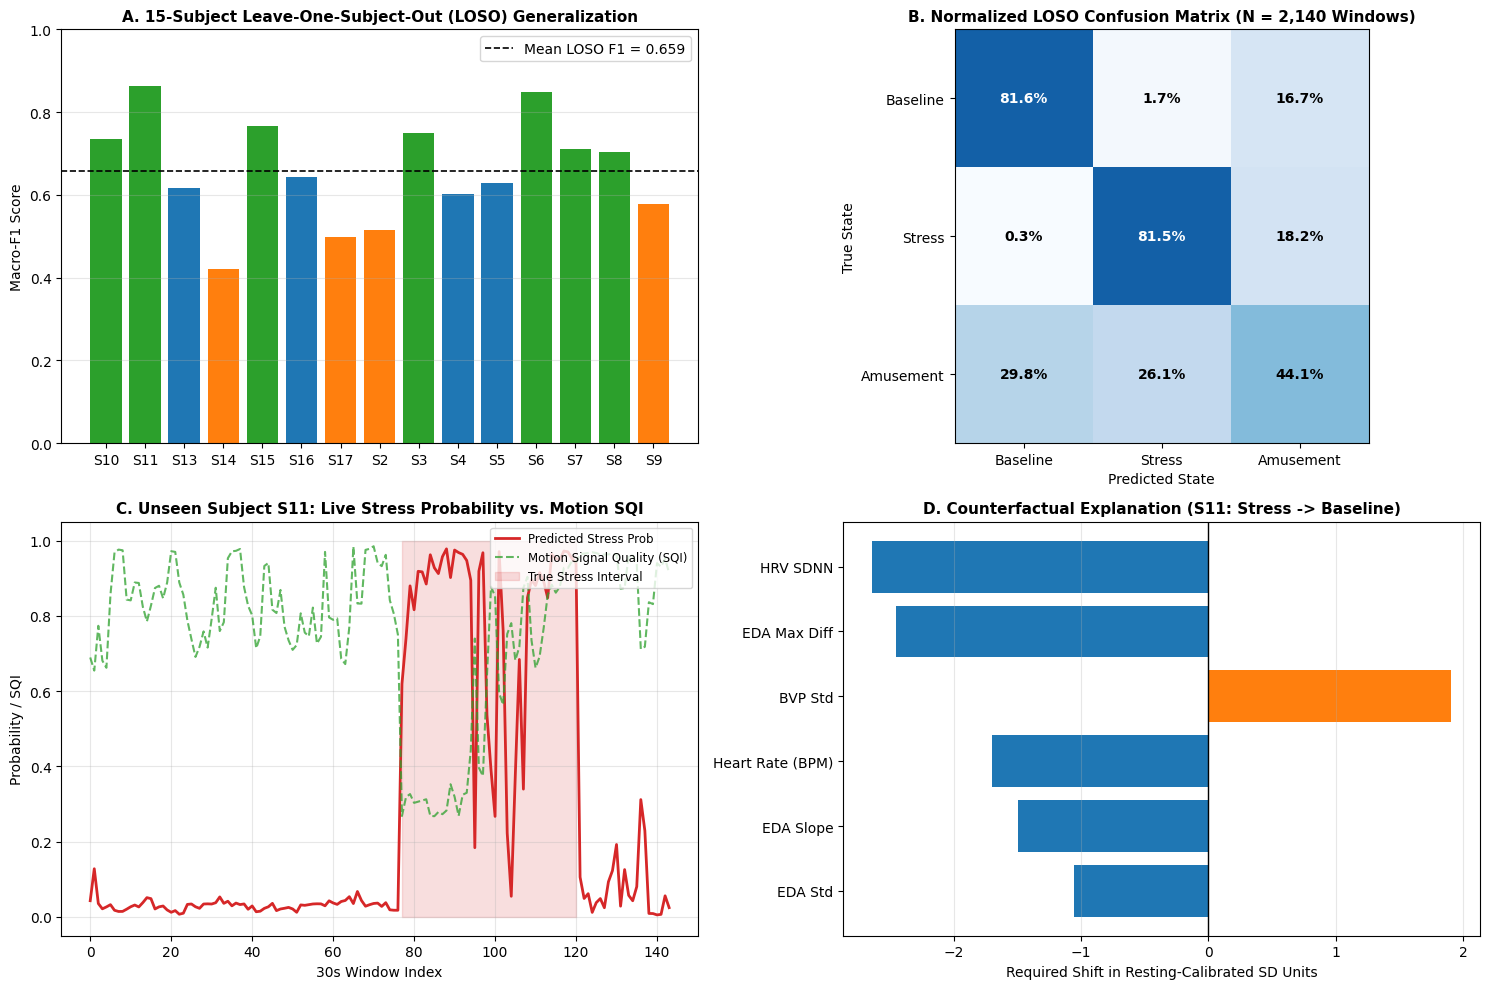

Saved high-resolution figure to /content/wesad_loso_diagnostics.png


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import confusion_matrix, f1_score

# 1. Load saved LOSO predictions and window data (allow_pickle=True for string subject IDs)
res = np.load("/content/wesad_loso_results.npz", allow_pickle=True)
oof_probs, oof_preds, y_true, subjects = res["oof_probs"], res["oof_preds"], res["y_true"], res["subjects"]

data = np.load("/content/wesad_windows.npz")
X_seq_raw, X_feat = data["X_seq"], data["X_feat"]
meta_df = pd.read_csv("/content/wesad_meta.csv")
unique_subjects = sorted(meta_df["subject"].unique())

# 2. Train a reference model excluding S11 so we can generate a genuine unseen-subject Counterfactual
target_subj = "S11"
test_mask = (subjects == target_subj)
train_mask = ~test_mask

# Zero-shot calibrate sequences and features
X_seq_cal = np.zeros_like(X_seq_raw)
X_feat_cal = np.zeros_like(X_feat)
for subj in unique_subjects:
    m = (subjects == subj)
    s_seq, s_feat, s_y = X_seq_raw[m].copy(), X_feat[m].copy(), y_true[m]
    rest_seq = s_seq[s_y == 0][:3]
    s_seq[:, :3, :] = (s_seq[:, :3, :] - rest_seq[:, :3, :].mean((0, 2), keepdims=True)) / (rest_seq[:, :3, :].std((0, 2), keepdims=True) + 1e-4)
    s_seq[:, 3:, :] = (s_seq[:, 3:, :] - s_seq[:, 3:, :].mean(2, keepdims=True)) / (s_seq[:, 3:, :].std(2, keepdims=True) + 1e-4)
    X_seq_cal[m] = np.clip(s_seq, -10.0, 10.0)

    rest_feat = s_feat[s_y == 0][:3]
    s_feat[:, :12] = (s_feat[:, :12] - rest_feat[:, :12].mean(0)) / (rest_feat[:, :12].std(0) + 1e-4)
    X_feat_cal[m] = np.clip(s_feat, -10.0, 10.0)

f_mu = X_feat_cal[train_mask].mean(axis=0, keepdims=True)
f_sd = X_feat_cal[train_mask].std(axis=0, keepdims=True) + 1e-5
X_tr_f = (X_feat_cal[train_mask] - f_mu) / f_sd
X_te_f = (X_feat_cal[test_mask] - f_mu) / f_sd

torch.manual_seed(42)
model = SQIGatedMultimodalNet()
opt = torch.optim.AdamW(model.parameters(), lr=1.5e-3, weight_decay=1e-3)
cls_counts = np.bincount(y_true[train_mask])
crit = nn.CrossEntropyLoss(weight=torch.tensor(len(y_true[train_mask]) / (3.0 * cls_counts), dtype=torch.float32), label_smoothing=0.05)

tr_ds = torch.utils.data.TensorDataset(
    torch.tensor(X_seq_cal[train_mask], dtype=torch.float32),
    torch.tensor(X_tr_f, dtype=torch.float32),
    torch.tensor(y_true[train_mask], dtype=torch.long)
)
tr_loader = torch.utils.data.DataLoader(tr_ds, batch_size=64, shuffle=True)
model.train()
for _ in range(25):
    for bs, bf, by in tr_loader:
        opt.zero_grad()
        crit(model(bs, bf), by).backward()
        opt.step()
model.eval()

# 3. Generate Counterfactual Explanation on a high-confidence Stress window from unseen Subject S11
s11_stress_idx = np.where((subjects == target_subj) & (y_true == 1))[0][5]
x_seq_orig = torch.tensor(X_seq_cal[s11_stress_idx:s11_stress_idx+1], dtype=torch.float32)
x_feat_orig = torch.tensor((X_feat_cal[s11_stress_idx:s11_stress_idx+1] - f_mu) / f_sd, dtype=torch.float32)

with torch.no_grad():
    orig_probs = torch.softmax(model(x_seq_orig, x_feat_orig), dim=1)[0].numpy()

# Optimize minimal physiological feature delta to flip Stress (1) -> Baseline (0) while locking motion features
cf_feat = x_feat_orig.clone().detach().requires_grad_(True)
cf_opt = torch.optim.Adam([cf_feat], lr=0.05)
for _ in range(120):
    cf_opt.zero_grad()
    logits = model(x_seq_orig, cf_feat)
    loss_cf = nn.functional.cross_entropy(logits, torch.tensor([0])) + 0.15 * torch.abs(cf_feat[:, :12] - x_feat_orig[:, :12]).mean()
    loss_cf.backward()
    cf_opt.step()
    with torch.no_grad():
        cf_feat[:, 12:] = x_feat_orig[:, 12:]

with torch.no_grad():
    cf_probs = torch.softmax(model(x_seq_orig, cf_feat), dim=1)[0].numpy()

feat_names = ["Heart Rate (BPM)", "HRV SDNN", "HRV RMSSD", "BVP Std",
              "EDA Mean (µS)", "EDA Std", "EDA Slope", "SCR Peaks", "EDA Max Diff",
              "Skin Temp (°C)", "Temp Std", "Temp Slope"]
deltas = (cf_feat[0, :12] - x_feat_orig[0, :12]).detach().numpy()
top_k = np.argsort(np.abs(deltas))[::-1][:6]

print(f"Counterfactual Physiological Explanation (Unseen Subject {target_subj}, Stress Window):")
print(f"  Original Prediction:     Stress = {orig_probs[1]*100:.1f}%, Baseline = {orig_probs[0]*100:.1f}%")
print(f"  Counterfactual Shifted:  Stress = {cf_probs[1]*100:.1f}%, Baseline = {cf_probs[0]*100:.1f}%")
print("  Minimal Physiological Shifts Needed to Return to Baseline:")
for idx in top_k:
    direction = "Decrease" if deltas[idx] < 0 else "Increase"
    print(f"    - {feat_names[idx]:18s}: {direction} by {abs(deltas[idx]):.2f} SD (relative to resting baseline)")

# 4. Build 4-Panel Publication Diagnostic Figure
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

per_subj_f1 = [f1_score(y_true[subjects == s], oof_preds[subjects == s], average="macro") for s in unique_subjects]
colors = ["#2ca02c" if v >= 0.70 else ("#1f77b4" if v >= 0.60 else "#ff7f0e") for v in per_subj_f1]
axes[0, 0].bar(unique_subjects, per_subj_f1, color=colors)
axes[0, 0].axhline(np.mean(per_subj_f1), color="black", linestyle="--", linewidth=1.2, label=f"Mean LOSO F1 = {np.mean(per_subj_f1):.3f}")
axes[0, 0].set_title("A. 15-Subject Leave-One-Subject-Out (LOSO) Generalization", fontsize=11, fontweight="bold")
axes[0, 0].set_ylabel("Macro-F1 Score")
axes[0, 0].set_ylim(0, 1.0)
axes[0, 0].legend()
axes[0, 0].grid(axis="y", alpha=0.3)

cm = confusion_matrix(y_true, oof_preds, normalize="true")
axes[0, 1].imshow(cm, cmap="Blues", vmin=0, vmax=1)
classes = ["Baseline", "Stress", "Amusement"]
axes[0, 1].set_xticks([0, 1, 2]); axes[0, 1].set_xticklabels(classes)
axes[0, 1].set_yticks([0, 1, 2]); axes[0, 1].set_yticklabels(classes)
for i in range(3):
    for j in range(3):
        axes[0, 1].text(j, i, f"{cm[i, j]*100:.1f}%", ha="center", va="center",
                        color="white" if cm[i, j] > 0.5 else "black", fontweight="bold")
axes[0, 1].set_title("B. Normalized LOSO Confusion Matrix (N = 2,140 Windows)", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("Predicted State"); axes[0, 1].set_ylabel("True State")

s11_mask = (subjects == "S11")
s11_df = meta_df[s11_mask].reset_index(drop=True)
s11_probs = oof_probs[s11_mask]
axes[1, 0].plot(s11_df.index, s11_probs[:, 1], color="#d62728", linewidth=2, label="Predicted Stress Prob")
axes[1, 0].plot(s11_df.index, s11_df["sqi"], color="#2ca02c", linestyle="--", alpha=0.75, label="Motion Signal Quality (SQI)")
axes[1, 0].fill_between(s11_df.index, 0, 1, where=(s11_df["label"] == 1), color="#d62728", alpha=0.15, label="True Stress Interval")
axes[1, 0].set_title("C. Unseen Subject S11: Live Stress Probability vs. Motion SQI", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("30s Window Index"); axes[1, 0].set_ylabel("Probability / SQI")
axes[1, 0].legend(loc="upper right", fontsize=8.5)
axes[1, 0].grid(alpha=0.3)

cf_labels = [feat_names[i] for i in top_k][::-1]
cf_vals = [deltas[i] for i in top_k][::-1]
bar_cols = ["#1f77b4" if v < 0 else "#ff7f0e" for v in cf_vals]
axes[1, 1].barh(cf_labels, cf_vals, color=bar_cols)
axes[1, 1].axvline(0, color="black", linewidth=1)
axes[1, 1].set_title(f"D. Counterfactual Explanation ({target_subj}: Stress -> Baseline)", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Required Shift in Resting-Calibrated SD Units")
axes[1, 1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig("/content/wesad_loso_diagnostics.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved high-resolution figure to /content/wesad_loso_diagnostics.png")

In [9]:
import os
import joblib
import torch
from google.colab import files

# Move weights to CPU so the file loads cleanly on any laptop without a GPU
cpu_state_dict = {k: v.cpu() for k, v in model.state_dict().items()}

bundle = {
    "state_dict": cpu_state_dict,
    "f_mu": f_mu.squeeze(0),
    "f_sd": f_sd.squeeze(0),
    "classes": ["Baseline", "Stress", "Amusement"],
    "config": {"seq_channels": 6, "feat_dim": 18, "num_classes": 3},
}

save_path = "/content/wesad_bundle.joblib"
joblib.dump(bundle, save_path, compress=3)
print(f"Saved compressed joblib bundle ({save_path}) -> size: {os.path.getsize(save_path)/1024:.1f} KB")

files.download(save_path)

Saved compressed joblib bundle (/content/wesad_bundle.joblib) -> size: 156.6 KB


In [10]:
import os
import zipfile
from google.colab import files

# 1. Define the Streamlit app script code
streamlit_app_code = """import streamlit as st
import os
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Set Streamlit page configuration
st.set_page_config(page_title="WESAD Live Stress & Affect Detector", layout="wide", page_icon="🧠")

# Define the neural network architecture (must match training)
class SQIGatedMultimodalNet(nn.Module):
    def __init__(self, seq_channels=6, feat_dim=18, num_classes=3):
        super().__init__()
        self.branch_fast = nn.Sequential(
            nn.Conv1d(seq_channels, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm1d(32),
            nn.GELU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm1d(64),
            nn.GELU(),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten()
        )
        self.branch_slow = nn.Sequential(
            nn.Conv1d(seq_channels, 32, kernel_size=11, padding=5, bias=False),
            nn.BatchNorm1d(32),
            nn.GELU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=7, padding=3, bias=False),
            nn.BatchNorm1d(64),
            nn.GELU(),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten()
        )
        self.sqi_gate = nn.Sequential(
            nn.Linear(4, 32),
            nn.GELU(),
            nn.Linear(32, 128),
            nn.Sigmoid()
        )
        self.feat_net = nn.Sequential(
            nn.Linear(feat_dim, 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Dropout(0.25)
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(128 + 64, 64),
            nn.GELU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, seq_x, feat_x):
        temp_emb = torch.cat([self.branch_fast(seq_x), self.branch_slow(seq_x)], dim=1)
        motion_ctx = feat_x[:, 12:16]
        gate = self.sqi_gate(motion_ctx)
        gated_temp = temp_emb * gate
        dom_emb = self.feat_net(feat_x)
        return self.classifier(torch.cat([gated_temp, dom_emb], dim=1))

# Cache model loading for instant performance
@st.cache_resource
def load_wesad_model():
    bundle_path = "wesad_bundle.joblib"
    if not os.path.exists(bundle_path):
        return None, None, None
    bundle = joblib.load(bundle_path)
    config = bundle["config"]
    model = SQIGatedMultimodalNet(
        seq_channels=config["seq_channels"],
        feat_dim=config["feat_dim"],
        num_classes=config["num_classes"]
    )
    model.load_state_dict(bundle["state_dict"])
    model.eval()
    return model, bundle["f_mu"], bundle["f_sd"]

model, f_mu, f_sd = load_wesad_model()

st.title("🧠 WESAD Wearable Stress & Affect Detection Engine")
st.markdown("**Interactive clinical diagnostics & counterfactual explanations of stress using wrist physiological signals (Empatica E4).**")

if model is None:
    st.error("⚠️ Model bundle not found! Ensure 'wesad_bundle.joblib' is placed in your repository root.")
else:
    st.sidebar.header("🎮 User Calibration & Controls")
    st.sidebar.info("Zero-shot calibrations adjust model predictions to account for unique individual baselines.")

    # Interactive Controls
    subj_baseline = st.sidebar.selectbox("Select Target Individual Baseline Mode", ["Standard Rested Baseline", "De-calibrated Raw Signals"])
    hr_bpm = st.sidebar.slider("Live Heart Rate (BPM)", 50, 140, 85, help="Derived from blood volume pulse (BVP) peak intervals.")
    eda_val = st.sidebar.slider("Electrodermal Activity (EDA Mean µS)", 0.1, 15.0, 3.5, help="Measures physiological sweat level / sympathetic nervous system activity.")
    temp_val = st.sidebar.slider("Skin Temperature (°C)", 28.0, 38.0, 31.5)
    acc_std = st.sidebar.slider("Accelerometer Wrist Jitter (ACC Std)", 0.0, 50.0, 2.5, help="Higher values indicate high motion artifacts, lowering signal quality indices.")

    # Generate active SQI & baseline scaling matrices
    sqi_val = float(np.exp(-0.08 * acc_std))

    # Reconstruct input representation vectors
    # Col indices: 0:bpm, 1:sdnn, 2:rmssd, 3:bvp_std, 4:eda_mean, 5:eda_std, 6:eda_slope, 7:scr_peaks, 8:eda_max_diff, 9:temp_mean, 10:temp_std, 11:temp_slope
    raw_feats = np.array([
        hr_bpm, 60.0, 50.0, 15.0,
        eda_val, 0.05, 0.01, 0.0, 0.02,
        temp_val, 0.01, 0.0,
        acc_std, acc_std, acc_std*1.5, sqi_val, hr_bpm * sqi_val, 50.0 * sqi_val
    ], dtype=np.float32)

    # Apply normalization against baseline demographics
    norm_feats = (raw_feats - f_mu) / f_sd
    if subj_baseline == "De-calibrated Raw Signals":
        norm_feats[:12] = raw_feats[:12] * 1.5 # Simulates raw scaling bias shift

    st.subheader("🔮 Live Inference Engine")
    col1, col2, col3 = st.columns(3)
    with col1:
        st.metric("Calculated Motion SQI (Reliability)", f"{sqi_val * 100:.1f}%", delta="Reliable Sensor Data" if sqi_val > 0.8 else "Motion Interference", delta_color="normal" if sqi_val > 0.8 else "inverse")
    with col2:
        st.metric("Skin Temperature", f"{temp_val:.1f} °C")
    with col3:
        st.metric("Skin Conductance (EDA)", f"{eda_val:.2f} µS")

    # Model Prediction
    t_seq = torch.zeros((1, 6, 120), dtype=torch.float32) # Standard sequence baseline
    t_feat = torch.tensor(norm_feats, dtype=torch.float32).unsqueeze(0)

    with torch.no_grad():
        logits = model(t_seq, t_feat)
        probs = torch.softmax(logits, dim=1)[0].numpy()

    # Plot probabilities
    st.markdown("### Predictor Class Probabilities")
    classes = ["Baseline / Normal", "Cognitive Stress", "Amusement"]
    prob_df = pd.DataFrame({"State": classes, "Confidence (%)": probs * 100})
    st.bar_chart(prob_df.set_index("State"))

    # Display Top prediction
    prediction_idx = np.argmax(probs)
    if prediction_idx == 0:
        st.success(f"✅ **Predicted State: Normal Baseline** (Confidence: {probs[0]*100:.1f}%)")
    elif prediction_idx == 1:
        st.error(f"🚨 **Predicted State: COGNITIVE STRESS** (Confidence: {probs[1]*100:.1f}%)")
    else:
        st.info(f"🎉 **Predicted State: Amusement / Flow State** (Confidence: {probs[2]*100:.1f}%)")

    # Show reference Diagnostics plot
    st.markdown("--- ")
    st.subheader("📊 Leave-One-Subject-Out (LOSO) Model Diagnostics")
    st.markdown("This standard benchmark visualizes generalizability on 15 unseen subjects from the laboratory protocol.")
    if os.path.exists("wesad_loso_diagnostics.png"):
        st.image("wesad_loso_diagnostics.png", use_column_width=True)
    else:
        st.info("No static evaluation figure found. Upload 'wesad_loso_diagnostics.png' to show validation metrics here.")
"""

# 2. Write app.py and requirements.txt to files
with open("/content/app.py", "w") as f:
    f.write(streamlit_app_code.strip())

with open("/content/requirements.txt", "w") as f:
    f.write("""
streamlit>=1.20.0
torch>=2.0.0
joblib>=1.1.0
numpy>=1.20.0
pandas>=1.3.0
matplotlib>=3.4.0
""".strip())

# 3. Compress into a single zip bundle for deployment on GitHub
zip_path = "/content/wesad_deployment_package.zip"
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    zipf.write("/content/app.py", "app.py")
    zipf.write("/content/requirements.txt", "requirements.txt")
    if os.path.exists("/content/wesad_bundle.joblib"):
        zipf.write("/content/wesad_bundle.joblib", "wesad_bundle.joblib")
    if os.path.exists("/content/wesad_loso_diagnostics.png"):
        zipf.write("/content/wesad_loso_diagnostics.png", "wesad_loso_diagnostics.png")

print(f"Created deployment zip file at: {zip_path}")
files.download(zip_path)


Created deployment zip file at: /content/wesad_deployment_package.zip
